# Cesta Básica: análise exploratória e agrupamento KMeans

Esta é a versão em português do fluxo. A análise mostra como os dados foram tratados, como a cesta nacional foi calculada, como os clusters foram formados e como interpretar outliers e mudanças mensais.

O modelo principal usa as cinco features de preço da cesta. A visualização 3D usa três delas apenas para facilitar a leitura; os rótulos continuam vindo do KMeans completo.

# Cesta Básica: análise exploratória e KMeans

Este notebook percorre todo o pipeline. Cada seção responde a uma pergunta:

1. O que recebemos? (bronze)
2. Quais observações são utilizáveis e por quê? (silver)
3. Qual é a unidade analítica e quais features a descrevem? (gold)
4. Quais padrões aparecem nos dados? (EDA)
5. Como os estabelecimentos foram agrupados? (KMeans do scikit-learn)

O agrupamento é descritivo para o período observado; não é uma previsão.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import polars as pl

from cestameans.ingestion.csv import CSVDataSource
from cestameans.ingestion.parsing import parse_dates, parse_numbers, rename_columns
from cestameans.pipelines.transforms import TransformationPipeline
from cestameans.preprocessing.cleaning import calculate_unit_price, normalize_text
from cestameans.preprocessing.normalization import normalize_brands, normalize_products
from cestameans.preprocessing.outliers import flag_price_outliers
from cestameans.validation.rules import (
    flag_date_quality,
    flag_duplicates,
    flag_invalid_prices,
    flag_required_fields,
    flag_unit_price_mismatch,
    split_valid_rejected,
)
from cestameans.validation.quality import summarize_quality
from cestameans.features.aggregation import aggregate_monthly_prices
from cestameans.features.basket import build_basket_cube
from cestameans.features.economic import add_market_reference, add_relative_prices
from cestameans.features.establishment import build_establishment_month_features
from cestameans.features.temporal import add_monthly_changes
from cestameans.ml.preprocessing import MLPreprocessor
from cestameans.config import FeatureSpec, ModelConfig
from cestameans.evaluation.metrics import evaluate_clustering
from cestameans.evaluation.outliers import score_cluster_outliers
from cestameans.evaluation.selection import evaluate_k_range
from cestameans.models.sklearn_kmeans import SklearnKMeans

## 1. Configuração e dados de origem

A fonte é lida inicialmente de forma lazy e como texto. Isso preserva valores malformados para auditoria, evitando conversões ou exclusões silenciosas.

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INPUT_PATH = PROJECT_ROOT / "data" / "ICB_DADOS_2026.csv"
assert INPUT_PATH.exists(), f"Missing input: {INPUT_PATH}"
raw = CSVDataSource(INPUT_PATH).read()
raw.head().collect()

source_row_id,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK,source_file
u32,str,str,str,str,str,str,str,str,str
0,"""01/09/22""","""23/09/22""","""SUP_33""","""Carne Bovina Coxão Mole""",null,"""54.2""","""1""","""54.2""","""/home/rx78/Documents/Projects/…"
1,"""01/09/22""","""12/09/22""","""SUP_15""","""Carne Bovina Coxão Mole""",null,"""53.9""","""1""","""53.9""","""/home/rx78/Documents/Projects/…"
2,"""01/09/22""","""21/09/22""","""SUP_09""","""Carne Bovina Coxão Mole""",null,"""53.9""","""1""","""53.9""","""/home/rx78/Documents/Projects/…"
3,"""01/09/22""","""23/09/22""","""SUP_12""","""Carne Bovina Coxão Mole""",null,"""51.99""","""1""","""51.99""","""/home/rx78/Documents/Projects/…"
4,"""01/09/22""","""12/09/22""","""SUP_20""","""Carne Bovina Coxão Mole""",null,"""51.9""","""1""","""51.9""","""/home/rx78/Documents/Projects/…"


## 2. Camada bronze: interpretar sem perder a proveniência

Bronze keeps the original observation identity and source file. Dates and numeric values are parsed into additional typed columns while raw source columns remain available.

In [3]:
bronze_pipeline = TransformationPipeline([rename_columns, parse_dates, parse_numbers])
bronze = bronze_pipeline.run(raw)
bronze_sample = bronze.head(5).collect()
bronze_sample, bronze.select(pl.len()).collect()

(shape: (5, 15)
 ┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
 │ source_ro ┆ reference ┆ collectio ┆ establish ┆ … ┆ collectio ┆ package_p ┆ quantity_ ┆ reported │
 │ w_id      ┆ _month    ┆ n_date    ┆ ment_id   ┆   ┆ n_date_pa ┆ rice_valu ┆ value     ┆ _unit_pr │
 │ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ rse_faile ┆ e         ┆ ---       ┆ ice_valu │
 │ u32       ┆ date      ┆ date      ┆ str       ┆   ┆ d         ┆ ---       ┆ f64       ┆ e        │
 │           ┆           ┆           ┆           ┆   ┆ ---       ┆ f64       ┆           ┆ ---      │
 │           ┆           ┆           ┆           ┆   ┆ bool      ┆           ┆           ┆ f64      │
 ╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
 │ 0         ┆ 2022-09-0 ┆ 2022-09-2 ┆ SUP_33    ┆ … ┆ false     ┆ 54.2      ┆ 1.0       ┆ 54.2     │
 │           ┆ 1         ┆ 3         ┆           ┆   ┆           ┆

## 3. Camada silver: validação e auditabilidade

As regras rígidas definem quais linhas podem alimentar a camada de features. As linhas rejeitadas são preservadas separadamente, enquanto duplicatas e outliers permanecem visíveis para auditoria.

In [4]:
silver_pipeline = TransformationPipeline(
    [
        normalize_text,
        calculate_unit_price,
        normalize_brands,
        lambda frame: normalize_products(frame, None),
        flag_required_fields,
        flag_invalid_prices,
        flag_unit_price_mismatch,
        flag_date_quality,
        flag_duplicates,
        flag_price_outliers,
    ]
)
silver_flagged = silver_pipeline.run(bronze)
silver, silver_rejected = split_valid_rejected(silver_flagged)
quality = summarize_quality(silver_flagged)
quality

metric,value
str,i64
"""rows""",46264
"""columns""",31
"""missing_required_field""",0
"""invalid_price""",0
"""unit_price_mismatch""",0
"""month_mismatch""",0
"""duplicate_observation""",3565
"""is_price_outlier""",717


### Análise exploratória do silver

Antes da agregação, inspecionamos as observações que alimentam o cubo. Os gráficos mostram disponibilidade, flags de validação, frequência dos produtos e estabelecimentos observados por mês.

**Significado das colunas de validação:**
- `missing_required_field`: falta mês de referência, estabelecimento ou produto. É uma falha rígida e a linha é rejeitada.
- `invalid_price`: preço unitário ou quantidade é nulo, não finito ou não positivo. É uma falha rígida.
- `unit_price_mismatch`: o preço unitário calculado a partir do pacote diverge do preço unitário informado acima da tolerância de 1%. É uma falha rígida.
- `month_mismatch`: o mês da data de coleta não coincide com o mês de referência. É uma falha rígida.
- `duplicate_observation`: a chave de negócio (mês, estabelecimento, produto, marca, preço e quantidade) aparece mais de uma vez. A linha não é rejeitada automaticamente; na agregação usamos a mediana e mantemos `sample_count` para rastreabilidade.
- `is_price_outlier`: preço com modified z-score acima de 3,5 dentro do grupo produto-mês, somente quando o grupo tem pelo menos 10 linhas e MAD positivo. A linha é marcada para auditoria e não entra na agregação mensal.

Assim, as quatro primeiras flags formam a rejeição rígida. Duplicatas e outliers são controles de qualidade: não desaparecem da tabela silver, mas são tratados explicitamente antes de calcular as features.

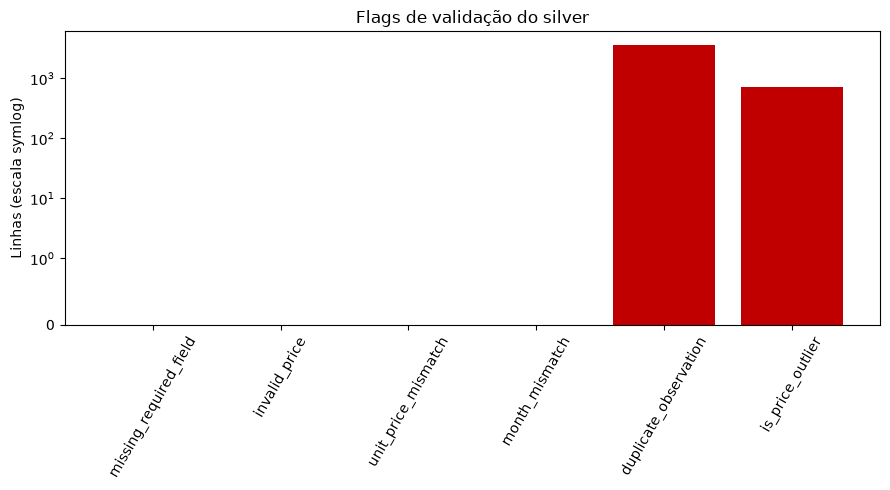

In [5]:
silver_df = silver_flagged.collect()
flag_columns = [
    "missing_required_field",
    "invalid_price",
    "unit_price_mismatch",
    "month_mismatch",
    "duplicate_observation",
    "is_price_outlier",
]
flag_counts = [
    (column, int(silver_df[column].fill_null(False).sum())) for column in flag_columns
]
fig, axis = plt.subplots(figsize=(9, 5))
axis.bar(
    [item[0] for item in flag_counts],
    [item[1] for item in flag_counts],
    color="#C00000",
)
axis.set_yscale("symlog", linthresh=1)
axis.set_title("Flags de validação do silver")
axis.set_ylabel("Linhas (escala symlog)")
axis.tick_params(axis="x", rotation=60)
plt.tight_layout()

In [6]:
silver_treatment = (
    silver_flagged.collect()
    .select(
        [
            "source_row_id",
            "reference_month",
            "establishment_id",
            "product",
            "package_price_value",
            "quantity_value",
            "unit_price",
            "missing_required_field",
            "invalid_price",
            "unit_price_mismatch",
            "month_mismatch",
            "duplicate_observation",
            "is_price_outlier",
        ]
    )
    .head(10)
)
silver_treatment

source_row_id,reference_month,establishment_id,product,package_price_value,quantity_value,unit_price,missing_required_field,invalid_price,unit_price_mismatch,month_mismatch,duplicate_observation,is_price_outlier
u32,date,str,str,f64,f64,f64,bool,bool,bool,bool,bool,bool
23,2022-09-01,"""SUP_38""","""Manteiga""",37.9,0.5,75.8,false,false,false,false,false,false
38,2022-09-01,"""SUP_15""","""Manteiga""",29.89,0.5,59.78,false,false,false,false,false,false
43,2022-09-01,"""SUP_15""","""Manteiga""",28.39,0.5,56.78,false,false,false,false,false,false
214,2022-09-01,"""SUP_39""","""Manteiga""",18.49,0.2,92.45,false,false,false,false,false,false
249,2022-09-01,"""SUP_32""","""Manteiga""",16.99,0.25,67.96,false,false,false,false,false,false
256,2022-09-01,"""SUP_09""","""Manteiga""",16.89,0.2,84.45,false,false,false,false,false,false
265,2022-09-01,"""SUP_51""","""Manteiga""",15.99,0.2,79.95,false,false,false,false,false,false
266,2022-09-01,"""SUP_34""","""Manteiga""",15.99,0.2,79.95,false,false,false,false,false,false
276,2022-09-01,"""SUP_33""","""Manteiga""",15.69,0.2,78.45,false,false,false,false,false,false


In [7]:
duplicate_key_columns = [
    "reference_month",
    "establishment_id",
    "product",
    "brand_name",
    "package_price_value",
    "quantity_value",
]
duplicate_groups = (
    silver_df.group_by(duplicate_key_columns)
    .agg(pl.len().alias("rows_in_group"))
    .filter(pl.col("rows_in_group") > 1)
)
duplicate_audit = pl.DataFrame(
    {
        "metric": ["linhas_marcadas", "grupos_duplicados", "linhas_excedentes"],
        "value": [
            int(silver_df["duplicate_observation"].fill_null(False).sum()),
            duplicate_groups.height,
            int((duplicate_groups["rows_in_group"] - 1).sum())
            if duplicate_groups.height
            else 0,
        ],
    }
)
duplicate_audit

metric,value
str,i64
"""linhas_marcadas""",3565
"""grupos_duplicados""",1630
"""linhas_excedentes""",1935


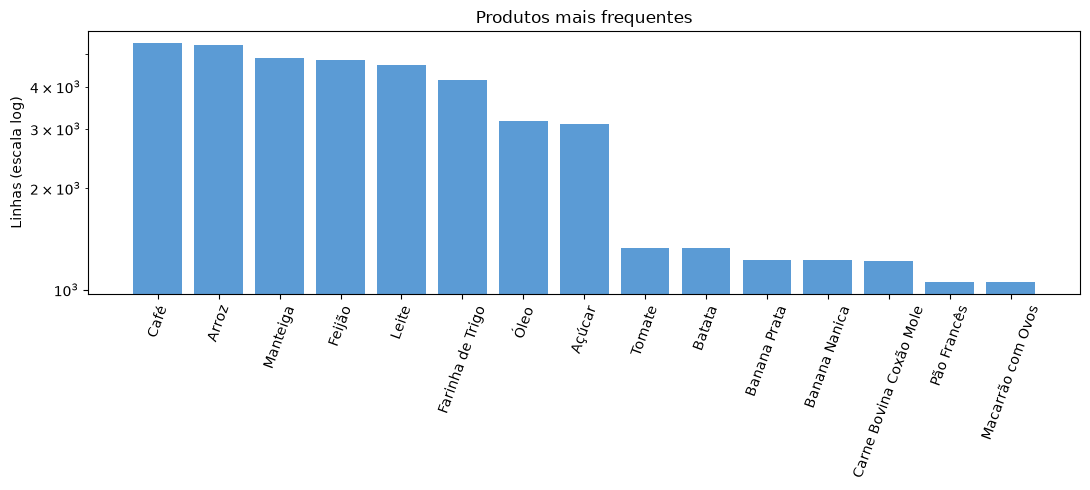

In [8]:
product_counts = (
    silver_df.group_by("product").len().sort("len", descending=True).head(15)
)
fig, axis = plt.subplots(figsize=(11, 5))
axis.bar(
    product_counts["product"].to_list(),
    product_counts["len"].to_list(),
    color="#5B9BD5",
)
axis.set_yscale("log")
axis.set_title("Produtos mais frequentes")
axis.set_ylabel("Linhas (escala log)")
axis.tick_params(axis="x", rotation=70)
plt.tight_layout()

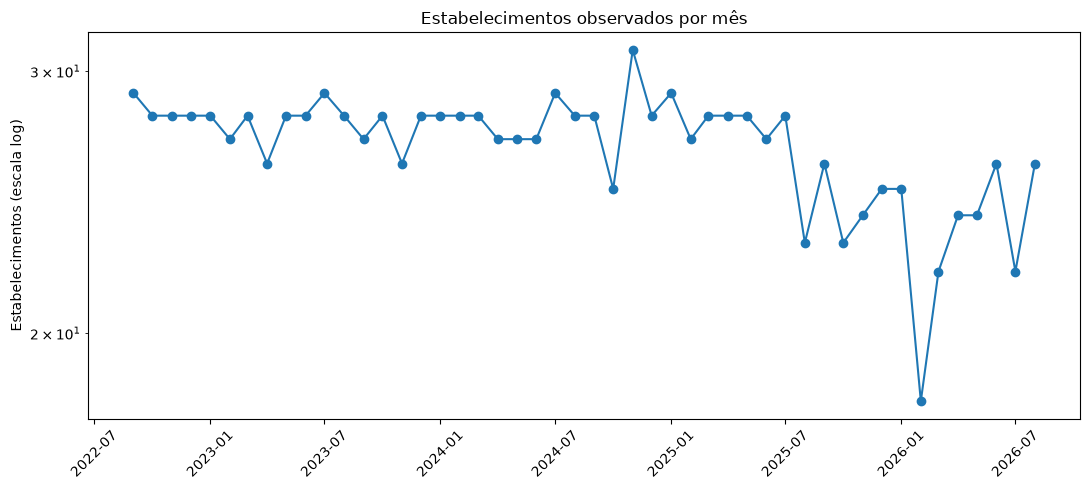

In [9]:
month_counts = (
    silver_df.group_by("reference_month")
    .agg(pl.col("establishment_id").n_unique().alias("establishments"))
    .sort("reference_month")
)
fig, axis = plt.subplots(figsize=(11, 5))
axis.plot(
    month_counts["reference_month"].to_list(),
    month_counts["establishments"].to_list(),
    marker="o",
)
axis.set_yscale("log")
axis.set_title("Estabelecimentos observados por mês")
axis.set_ylabel("Estabelecimentos (escala log)")
axis.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 4. Camada gold: features analíticas

A unidade analítica é um estabelecimento-mês. O cubo de produtos é agregado na cesta nacional usando as quantidades definidas em `data/reference/national_basket.csv`. Para cada categoria, usamos a mediana do preço unitário observado entre as variantes mapeadas e multiplicamos pela quantidade nacional. O custo é completo somente quando todas as categorias da definição estão presentes; caso contrário, mantemos custo parcial e cobertura.

Cada linha do cubo representa uma estimativa de cesta em um estabelecimento e mês. Neste dataset há 48 meses: em média observamos aproximadamente 27 cestas por mês e, considerando apenas as linhas com todas as categorias, aproximadamente 18 cestas nacionais completas por mês.

In [10]:
shared_features = TransformationPipeline(
    [
        aggregate_monthly_prices,
        lambda frame: add_market_reference(frame, min_stores=5),
        add_relative_prices,
        add_monthly_changes,
    ]
)
monthly_prices = aggregate_monthly_prices(silver).collect()
basket_definition = pl.read_csv(
    PROJECT_ROOT / "data" / "reference" / "national_basket.csv"
)
basket_cube = build_basket_cube(
    monthly_prices.lazy(), basket_definition, min_stores=5
).collect()
gold_lazy = build_establishment_month_features(shared_features.run(silver))
gold = gold_lazy.collect().join(
    basket_cube, on=["establishment_id", "reference_month"], how="left"
)
gold_model = gold.filter(pl.col("complete_basket").fill_null(False))
basket_definition, basket_cube.head(), gold.shape, gold_model.shape

(shape: (13, 4)
 ┌──────────┬─────────────────┬─────────────┬─────────────────────────────────┐
 │ category ┆ basket_quantity ┆ basket_unit ┆ source_products                 │
 │ ---      ┆ ---             ┆ ---         ┆ ---                             │
 │ str      ┆ f64             ┆ str         ┆ str                             │
 ╞══════════╪═════════════════╪═════════════╪═════════════════════════════════╡
 │ carne    ┆ 6.0             ┆ kg          ┆ Carne Acem|Carne Bovina Acem|C… │
 │ leite    ┆ 15.0            ┆ l           ┆ Leite                           │
 │ feijao   ┆ 4.5             ┆ kg          ┆ Feijão                          │
 │ arroz    ┆ 3.0             ┆ kg          ┆ Arroz                           │
 │ farinha  ┆ 1.5             ┆ kg          ┆ Farinha|Farinha de Trigo        │
 │ …        ┆ …               ┆ …           ┆ …                               │
 │ cafe     ┆ 0.6             ┆ kg          ┆ Café                            │
 │ banana   ┆ 90.0      

In [11]:
monthly_basket_counts = (
    basket_cube.group_by("reference_month")
    .agg(
        [
            pl.len().alias("cestas_observadas"),
            pl.col("complete_basket").fill_null(False).sum().alias("cestas_completas"),
        ]
    )
    .sort("reference_month")
)
monthly_basket_summary = monthly_basket_counts.select(
    [
        pl.col("cestas_observadas").mean().alias("media_cestas_observadas_por_mes"),
        pl.col("cestas_completas").mean().alias("media_cestas_completas_por_mes"),
    ]
)
monthly_basket_summary

media_cestas_observadas_por_mes,media_cestas_completas_por_mes
f64,f64
26.6875,18.041667


## 5. Análise exploratória

Estas tabelas ajudam a entender escala, valores ausentes, dispersão e comportamento temporal antes do modelo. As cinco features usadas no KMeans são mostradas com estatísticas descritivas.

In [12]:
FEATURE_COLUMNS = [
    "basket_cost",
    "basket_cost_vs_market_pct",
    "basket_cost_mom_change",
    "mean_log_relative_price",
    "mean_relative_iqr",
]
gold.select(FEATURE_COLUMNS).describe()

statistic,basket_cost,basket_cost_vs_market_pct,basket_cost_mom_change,mean_log_relative_price,mean_relative_iqr
str,f64,f64,f64,f64,f64
"""count""",866.0,866.0,716.0,1281.0,1281.0
"""null_count""",415.0,415.0,565.0,0.0,0.0
"""mean""",1539.654737,0.861284,0.011475,-0.014851,1.001139
"""std""",206.324271,12.918753,0.121668,0.09814,0.719163
"""min""",969.487,-37.734388,-0.321362,-0.281255,0.0
"""25%""",1391.868167,-7.51895,-0.047209,-0.094923,0.543678
"""50%""",1520.560333,0.0,0.003245,0.002694,0.823801
"""75%""",1689.753333,9.072635,0.057382,0.06298,1.207265
"""max""",2450.340333,52.03826,0.649076,0.205331,6.775


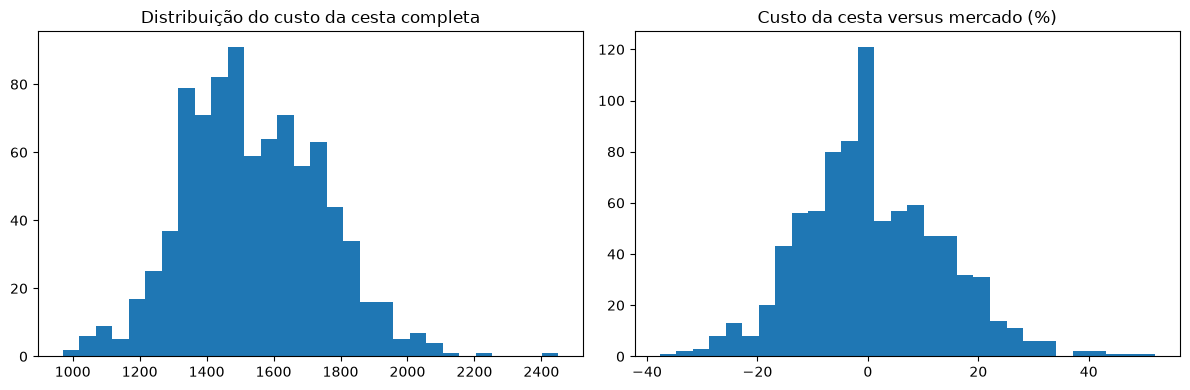

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(gold["basket_cost"].drop_nulls().to_numpy(), bins=30)
axes[1].hist(gold["basket_cost_vs_market_pct"].drop_nulls().to_numpy(), bins=30)
axes[0].set_title("Distribuição do custo da cesta completa")
axes[1].set_title("Custo da cesta versus mercado (%)")
plt.tight_layout()

### Gráficos de distribuição

Histograms show the shape of each feature. Skewed or heavy-tailed features can make distance-based clustering sensitive to extreme observations, which is one reason robust scaling is used later.

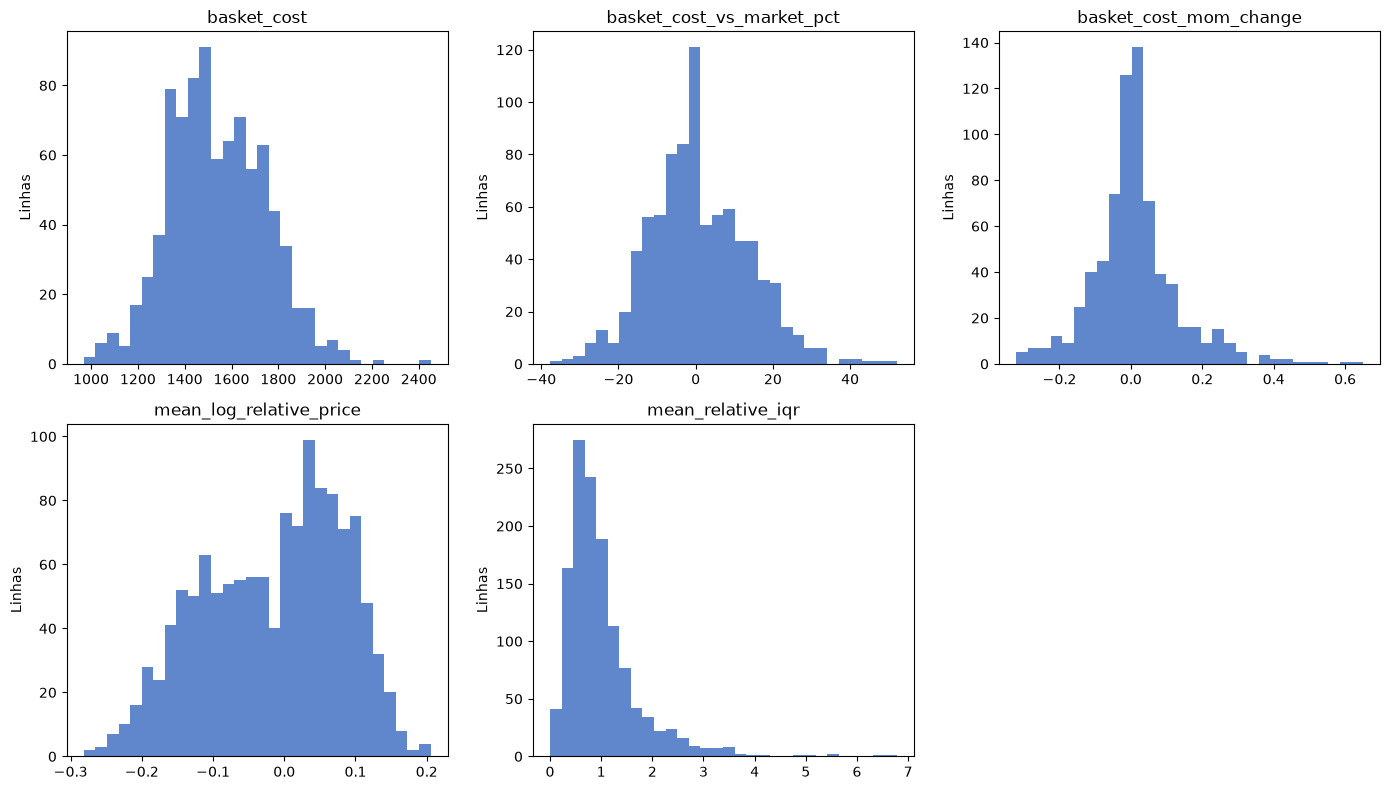

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for axis, column in zip(axes.flat, FEATURE_COLUMNS):
    values = gold[column].drop_nulls().to_numpy()
    axis.hist(values, bins=30, color="#4472C4", alpha=0.85)
    axis.set_title(column)
    axis.set_ylabel("Linhas")
axes.flat[-1].axis("off")
plt.tight_layout()

### Boxplots

Boxplots compare medians, interquartile ranges, and extreme values on one figure. The points outside the whiskers are not automatically removed; they should be investigated alongside the source quality flags.

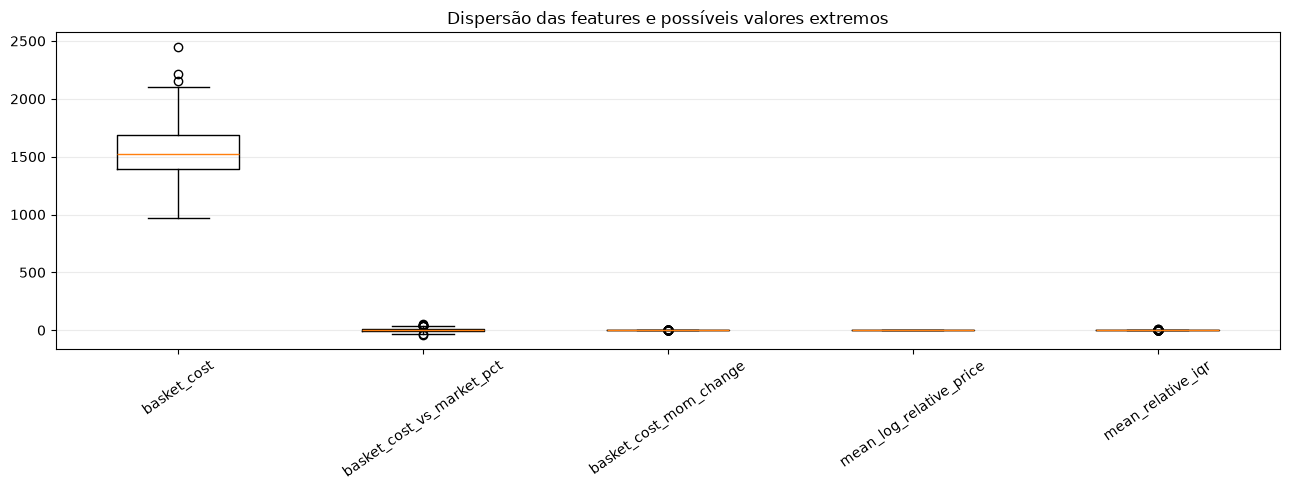

In [15]:
fig, axis = plt.subplots(figsize=(13, 5))
box_data = [gold[column].drop_nulls().to_numpy() for column in FEATURE_COLUMNS]
axis.boxplot(box_data, tick_labels=FEATURE_COLUMNS, showfliers=True)
axis.set_title("Dispersão das features e possíveis valores extremos")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()

## 6. Pré-processamento e seleção de K

O KMeans usa distâncias; por isso as features precisam estar em escalas comparáveis. Usamos imputação pela mediana e escala robusta. A inércia sempre diminui quando K cresce, então analisamos o silhouette junto com ela, em vez de escolher K apenas pela inércia.

In [16]:
feature_spec = FeatureSpec(
    name="establishment_month", columns=tuple(FEATURE_COLUMNS), min_products=1
)
preprocessor = MLPreprocessor(feature_spec, scaler="robust")
X, keys = preprocessor.select(gold_model)
X_scaled = preprocessor.fit_transform(X)
model_config = ModelConfig(backend="sklearn", n_clusters=5, seed=42)
k_diagnostics = evaluate_k_range(X_scaled, model_config, tuple(range(2, 9)))
k_diagnostics

k,inertia,silhouette,davies_bouldin,calinski_harabasz
i64,f64,f64,f64,f64
2,3177.269463,0.248295,1.446262,316.942952
3,2519.697485,0.247308,1.3129,312.206578
4,2065.377589,0.274978,1.128312,316.831964
5,1717.406736,0.280976,1.075774,329.055161
6,1567.231453,0.232902,1.154118,304.611517
7,1428.944569,0.236088,1.129088,291.94397
8,1316.656544,0.239294,1.132354,281.753572


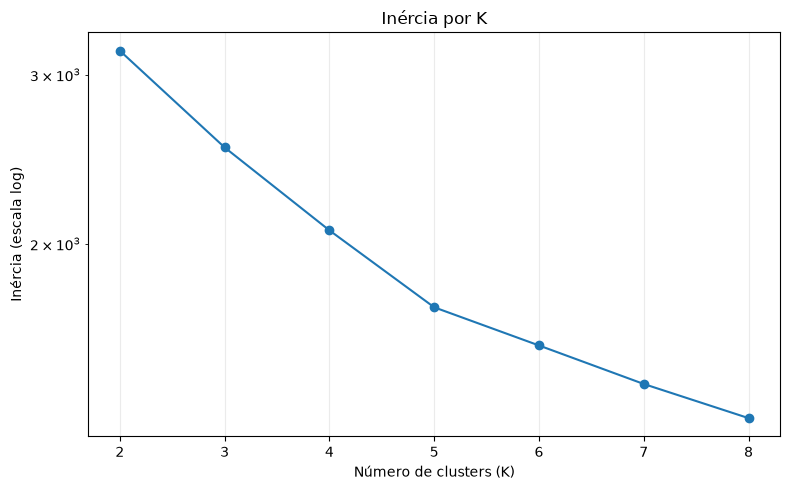

In [17]:
fig, axis = plt.subplots(figsize=(8, 5))
axis.plot(k_diagnostics["k"], k_diagnostics["inertia"], marker="o")
axis.set_yscale("log")
axis.set(
    title="Inércia por K",
    xlabel="Número de clusters (K)",
    ylabel="Inércia (escala log)",
)
axis.grid(alpha=0.25)
plt.tight_layout()

A curva de inércia mede a soma das distâncias quadráticas dentro dos clusters. Ela sempre diminui quando K aumenta; por isso procuramos um cotovelo ou retornos decrescentes, e não o menor valor absoluto.

Neste caso, K=5 é escolhido porque apresenta o maior silhouette entre K=4, 5, 6, 7 e 8 e também melhora o índice Davies-Bouldin. K=7 ou K=8 reduzem a inércia, como sempre acontece ao adicionar clusters, mas pioram a separação média e podem fragmentar perfis que já são suficientemente distintos. A escolha deve ser revisada se a finalidade analítica mudar.

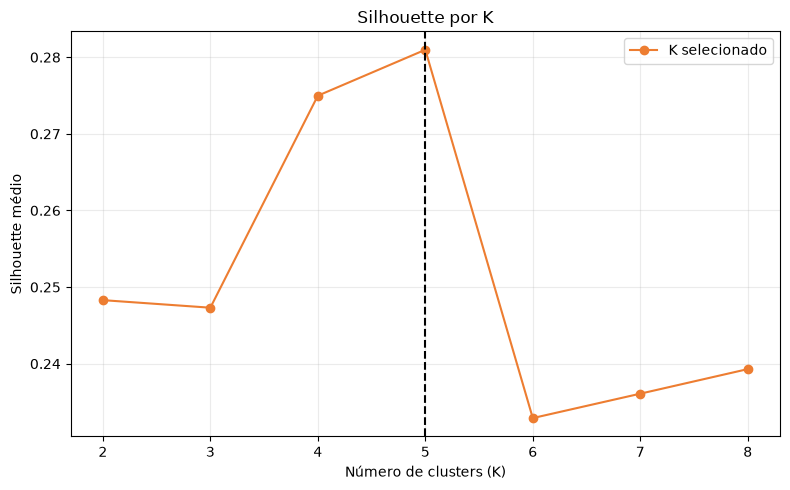

In [18]:
fig, axis = plt.subplots(figsize=(8, 5))
axis.plot(k_diagnostics["k"], k_diagnostics["silhouette"], marker="o", color="#ED7D31")
axis.set(
    title="Silhouette por K", xlabel="Número de clusters (K)", ylabel="Silhouette médio"
)
axis.axvline(model_config.n_clusters, color="black", linestyle="--", label="Selected K")
axis.legend(["K selecionado"])
axis.grid(alpha=0.25)
plt.tight_layout()

## 7. Modelo KMeans e interpretação

Os rótulos dos clusters são identificadores arbitrários. A interpretação vem da comparação do perfil de features de cada cluster com o significado das features, e não do número do rótulo.

In [19]:
model = SklearnKMeans(model_config).fit(X_scaled)
labels = model.predict(X_scaled)
assignments = keys.with_columns(pl.Series("cluster", labels))
metrics = evaluate_clustering(X_scaled, labels, model.inertia)
outlier_scores = score_cluster_outliers(X_scaled, labels, model.centroids)
outliers = keys.hstack(outlier_scores)
profiles = (
    gold_model.join(assignments, on=["establishment_id", "reference_month"])
    .group_by("cluster")
    .agg(
        [pl.col(c).mean().alias(f"mean_{c}") for c in FEATURE_COLUMNS]
        + [pl.len().alias("rows")]
    )
    .sort("cluster")
)
metrics, profiles

({'inertia': 1717.4067355394272,
  'silhouette': 0.2809757415722046,
  'davies_bouldin': 1.075774486698006,
  'calinski_harabasz': 329.05516124717246},
 shape: (5, 7)
 ┌─────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┬──────┐
 │ cluster ┆ mean_basket_co ┆ mean_basket_co ┆ mean_basket_c ┆ mean_mean_log ┆ mean_mean_rel ┆ rows │
 │ ---     ┆ st             ┆ st_vs_market_p ┆ ost_mom_chang ┆ _relative_pri ┆ ative_iqr     ┆ ---  │
 │ i64     ┆ ---            ┆ ct             ┆ e             ┆ ce            ┆ ---           ┆ u32  │
 │         ┆ f64            ┆ ---            ┆ ---           ┆ ---           ┆ f64           ┆      │
 │         ┆                ┆ f64            ┆ f64           ┆ f64           ┆               ┆      │
 ╞═════════╪════════════════╪════════════════╪═══════════════╪═══════════════╪═══════════════╪══════╡
 │ 0       ┆ 1390.024622    ┆ -7.90953       ┆ -0.156113     ┆ -0.015516     ┆ 0.827897      ┆ 111  │
 │ 1       ┆ 1724

In [20]:
# Detalhes dos produtos que compõem cada cesta estabelecimento-mês.
import plotly.graph_objects as go
from plotly.colors import qualitative

palette = qualitative.Set2
feature_labels = {
    "basket_cost": "Custo da cesta (R$)",
    "basket_cost_vs_market_pct": "Custo versus mercado (%)",
    "basket_cost_mom_change": "Variação mensal",
    "mean_log_relative_price": "Preço relativo médio (log)",
    "mean_relative_iqr": "IQR relativo médio",
}
plot_3d_data = (
    gold_model.select(["establishment_id", "reference_month", *FEATURE_COLUMNS])
    .with_columns(pl.Series("cluster", labels))
    .drop_nulls()
)
months = plot_3d_data["reference_month"].unique().sort().to_list()
basket_product_map = (
    basket_definition.with_columns(pl.col("source_products").str.split("|"))
    .explode("source_products")
    .rename({"source_products": "product"})
)
basket_detail_rows = (
    monthly_prices.join(basket_product_map, on="product", how="inner")
    .select(
        [
            "establishment_id",
            "reference_month",
            "category",
            "product",
            "median_price",
            "price_std",
            "sample_count",
            "basket_quantity",
            "basket_unit",
        ]
    )
    .to_dicts()
)
basket_detail_lookup = {}
for row in basket_detail_rows:
    key = (row["establishment_id"], row["reference_month"])
    basket_detail_lookup.setdefault(key, []).append(
        f"{row['category']}: {row['product']} = R$ {row['median_price']:.2f}; desvio={row['price_std'] if row['price_std'] is not None else 0:.2f}; n={row['sample_count']}; quantidade={row['basket_quantity']} {row['basket_unit']}"
    )
basket_detail_lookup = {
    key: "<br>".join(values) for key, values in basket_detail_lookup.items()
}
len(basket_detail_lookup)

1281

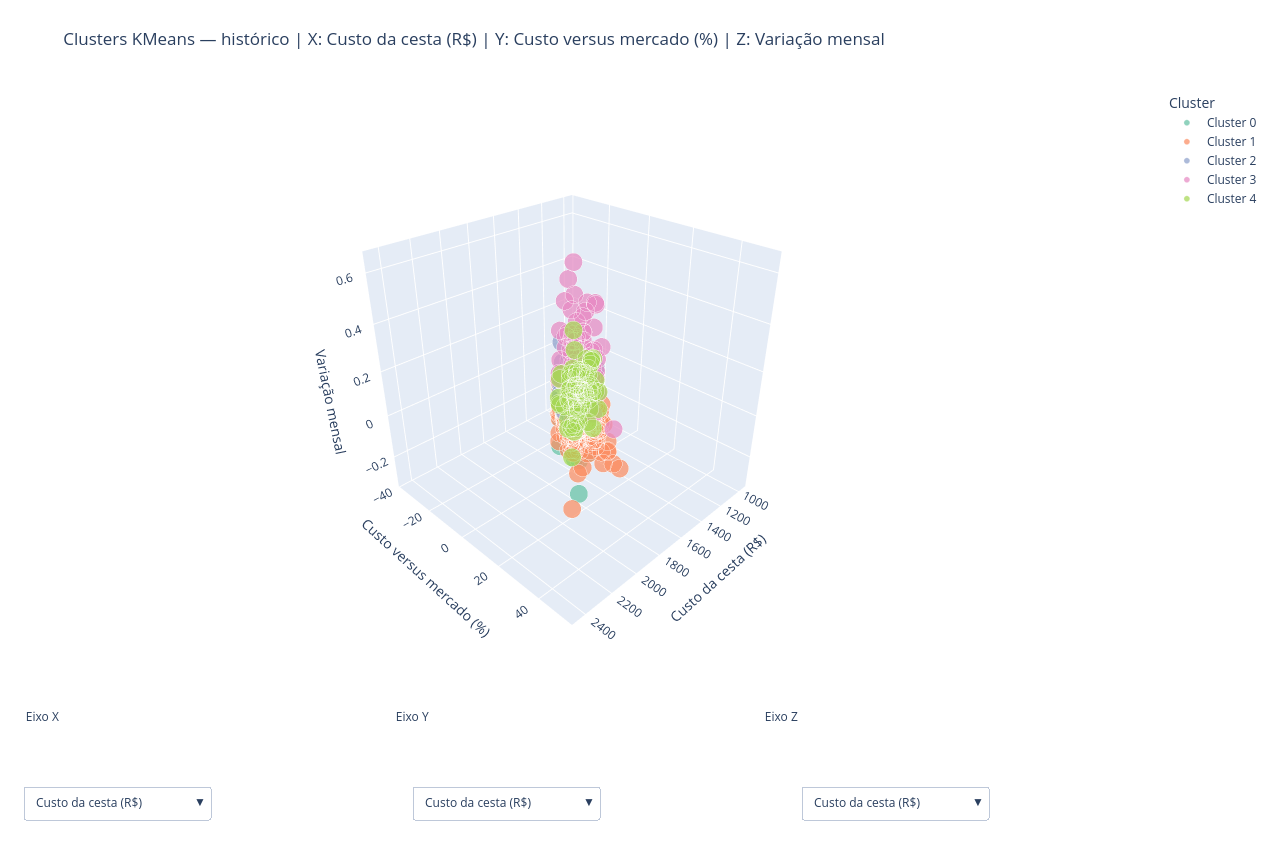

In [21]:
# Visualização histórica: todos os meses aparecem ao mesmo tempo.
# Há um menu independente para cada eixo.
def historical_cluster_traces(x_feature, y_feature, z_feature):
    traces = []
    for cluster in range(model_config.n_clusters):
        data = plot_3d_data.filter(pl.col("cluster") == cluster)
        traces.append(
            go.Scatter3d(
                x=data[x_feature].to_list(),
                y=data[y_feature].to_list(),
                z=data[z_feature].to_list(),
                mode="markers",
                name=f"Cluster {cluster}",
                marker={
                    "size": 6,
                    "color": palette[cluster % len(palette)],
                    "opacity": 0.72,
                    "line": {"width": 0.3, "color": "white"},
                },
                text=[
                    f"{store} | mês {month}"
                    for store, month in zip(
                        data["establishment_id"].to_list(),
                        data["reference_month"].to_list(),
                    )
                ],
                customdata=[
                    [
                        store,
                        month,
                        basket_detail_lookup.get(
                            (store, month), "Detalhes não disponíveis"
                        ),
                    ]
                    for store, month in zip(
                        data["establishment_id"].to_list(),
                        data["reference_month"].to_list(),
                    )
                ],
                hovertemplate="<b>%{customdata[0]}</b> | %{customdata[1]}<br>X: %{x:.3f}<br>Y: %{y:.3f}<br>Z: %{z:.3f}<br><br><b>Detalhes dos produtos</b><br>%{customdata[2]}<extra></extra>",
            )
        )
    return traces


historical_features = [
    "basket_cost",
    "basket_cost_vs_market_pct",
    "basket_cost_mom_change",
]
axis_names = ["X", "Y", "Z"]


def historical_axis_buttons(axis_index):
    buttons = []
    for feature in FEATURE_COLUMNS:
        selected = list(historical_features)
        selected[axis_index] = feature
        traces = historical_cluster_traces(*selected)
        buttons.append(
            {
                "label": feature_labels[feature],
                "method": "update",
                "args": [
                    {
                        "x": [trace.x for trace in traces],
                        "y": [trace.y for trace in traces],
                        "z": [trace.z for trace in traces],
                    },
                    {
                        "title": f"Clusters KMeans — histórico | X: {feature_labels[selected[0]]} | Y: {feature_labels[selected[1]]} | Z: {feature_labels[selected[2]]}",
                        "scene": {
                            "xaxis": {"title": feature_labels[selected[0]]},
                            "yaxis": {"title": feature_labels[selected[1]]},
                            "zaxis": {"title": feature_labels[selected[2]]},
                        },
                    },
                ],
            }
        )
    return buttons


fig_3d_history = go.Figure(data=historical_cluster_traces(*historical_features))
fig_3d_history.update_layout(
    title=f"Clusters KMeans — histórico | X: {feature_labels[historical_features[0]]} | Y: {feature_labels[historical_features[1]]} | Z: {feature_labels[historical_features[2]]}",
    height=850,
    width=1200,
    scene={
        "xaxis_title": feature_labels[historical_features[0]],
        "yaxis_title": feature_labels[historical_features[1]],
        "zaxis_title": feature_labels[historical_features[2]],
        "camera": {"eye": {"x": 1.6, "y": 1.6, "z": 1.3}},
    },
    updatemenus=[
        {
            "buttons": historical_axis_buttons(0),
            "direction": "down",
            "x": 0.02,
            "y": -0.20,
            "xanchor": "left",
            "yanchor": "top",
            "showactive": True,
            "bgcolor": "white",
        },
        {
            "buttons": historical_axis_buttons(1),
            "direction": "down",
            "x": 0.36,
            "y": -0.20,
            "xanchor": "left",
            "yanchor": "top",
            "showactive": True,
            "bgcolor": "white",
        },
        {
            "buttons": historical_axis_buttons(2),
            "direction": "down",
            "x": 0.70,
            "y": -0.20,
            "xanchor": "left",
            "yanchor": "top",
            "showactive": True,
            "bgcolor": "white",
        },
    ],
    annotations=[
        {
            "text": "Eixo X",
            "xref": "paper",
            "yref": "paper",
            "x": 0.02,
            "y": -0.10,
            "showarrow": False,
        },
        {
            "text": "Eixo Y",
            "xref": "paper",
            "yref": "paper",
            "x": 0.36,
            "y": -0.10,
            "showarrow": False,
        },
        {
            "text": "Eixo Z",
            "xref": "paper",
            "yref": "paper",
            "x": 0.70,
            "y": -0.10,
            "showarrow": False,
        },
    ],
    legend={"title": "Cluster"},
    margin={"l": 0, "r": 0, "b": 180, "t": 90},
)
fig_3d_history.show()

### Perfis e interpretação dos clusters

Os eixos do PCA são difíceis de interpretar diretamente. As tabelas e o heatmap abaixo descrevem cada cluster nas unidades originais da cesta. Valores positivos no heatmap significam que o cluster está acima da média entre clusters para a feature; valores negativos significam que está abaixo.

In [22]:
cluster_reading = profiles.select(
    [
        "cluster",
        "mean_basket_cost",
        "mean_basket_cost_vs_market_pct",
        "mean_basket_cost_mom_change",
        "mean_mean_log_relative_price",
        "mean_mean_relative_iqr",
        "rows",
    ]
).with_columns(pl.col("mean_basket_cost").rank().cast(pl.Int64).alias("cost_rank"))
cluster_reading.sort("cost_rank")

cluster,mean_basket_cost,mean_basket_cost_vs_market_pct,mean_basket_cost_mom_change,mean_mean_log_relative_price,mean_mean_relative_iqr,rows,cost_rank
i64,f64,f64,f64,f64,f64,u32,i64
0,1390.024622,-7.90953,-0.156113,-0.015516,0.827897,111,1
2,1403.061532,-7.853986,0.000187,-0.044892,0.774095,294,2
4,1486.846486,-1.648395,0.013597,0.019864,2.344273,103,3
3,1666.582348,8.459128,0.272619,0.025504,1.052134,67,4
1,1724.199221,12.150946,0.026016,0.075825,0.798386,291,5


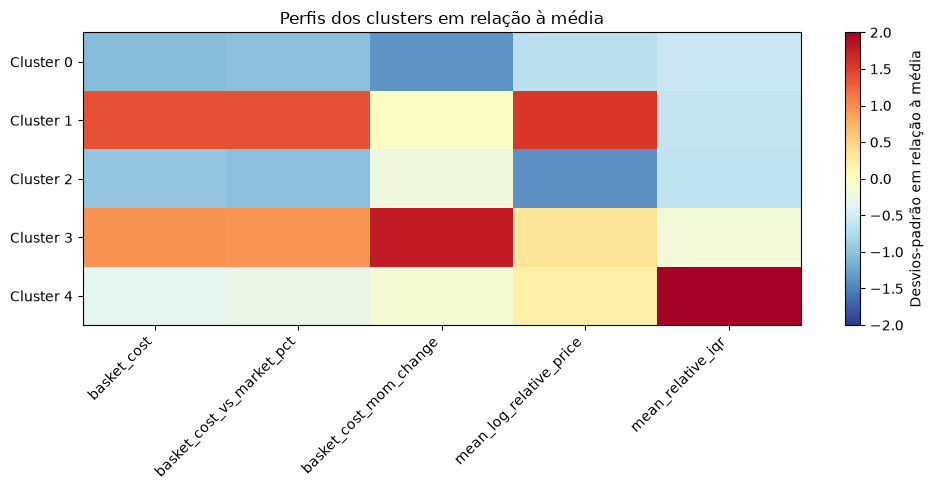

In [23]:
profile_matrix = profiles.select(
    [f"mean_{column}" for column in FEATURE_COLUMNS]
).to_numpy()
profile_z = (profile_matrix - profile_matrix.mean(axis=0)) / profile_matrix.std(axis=0)
fig, axis = plt.subplots(figsize=(10, 5))
image = axis.imshow(profile_z, cmap="RdYlBu_r", aspect="auto", vmin=-2, vmax=2)
axis.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=45, ha="right")
axis.set_yticks(
    range(profiles.height), [f"Cluster {value}" for value in profiles["cluster"]]
)
axis.set_title("Perfis dos clusters em relação à média")
fig.colorbar(image, ax=axis, label="Desvios-padrão em relação à média")
plt.tight_layout()

A interpretação deve começar pela tabela nas unidades originais: nível de custo, distância do mercado, movimento mensal, dispersão e tamanho do cluster. O heatmap é uma comparação compacta, não substitui os valores subjacentes.

### Relações entre features e fórmulas

O custo da cesta é construído como:

basket_cost(s,t) = sum over j of unit_price(s,t,j) * national_quantity(j)

A comparação com o mercado é:

basket_cost_vs_market_pct(s,t) = 100 * (basket_cost(s,t) / median_basket_cost(t) - 1)

Como a segunda grandeza usa `basket_cost` no numerador, essas duas features são naturalmente correlacionadas.

**Features usadas no KMeans:**
- `basket_cost`: nível absoluto de custo da cesta. É a dimensão mais direta do preço.
- `basket_cost_vs_market_pct`: posição relativa ao custo mediano do mercado no mesmo mês. Permite distinguir uma cesta cara porque o mês inteiro ficou caro de uma cesta cara em relação às demais.
- `basket_cost_mom_change`: variação mês a mês. Captura dinâmica, e não apenas nível.
- `mean_log_relative_price`: posição média dos produtos em relação ao mercado, reduzindo a influência de preços muito grandes.
- `mean_relative_iqr`: dispersão relativa dos preços observados. Ajuda a separar mercados homogêneos de mercados com grande heterogeneidade.

Portanto, `basket_cost_vs_market_pct` não substitui as outras features. Ele adiciona contexto; as outras três capturam movimento, posição dos produtos e dispersão. Features como cobertura da cesta não foram usadas como eixo principal porque a cobertura é praticamente constante nas cestas completas e funcionaria mais como controle de qualidade do que como perfil econômico. Os gráficos abaixo ajudam a avaliar se alguma feature é redundante.

O mercado aparece em porcentagem porque a fórmula é `100 * (custo_da_cesta / custo_mediano_do_mercado_no_mês - 1)`. Assim, 0% significa exatamente a mediana do mercado, +10% significa 10% acima dela e -10% significa 10% abaixo. A porcentagem torna a comparação mais útil entre meses com níveis gerais de preço diferentes.

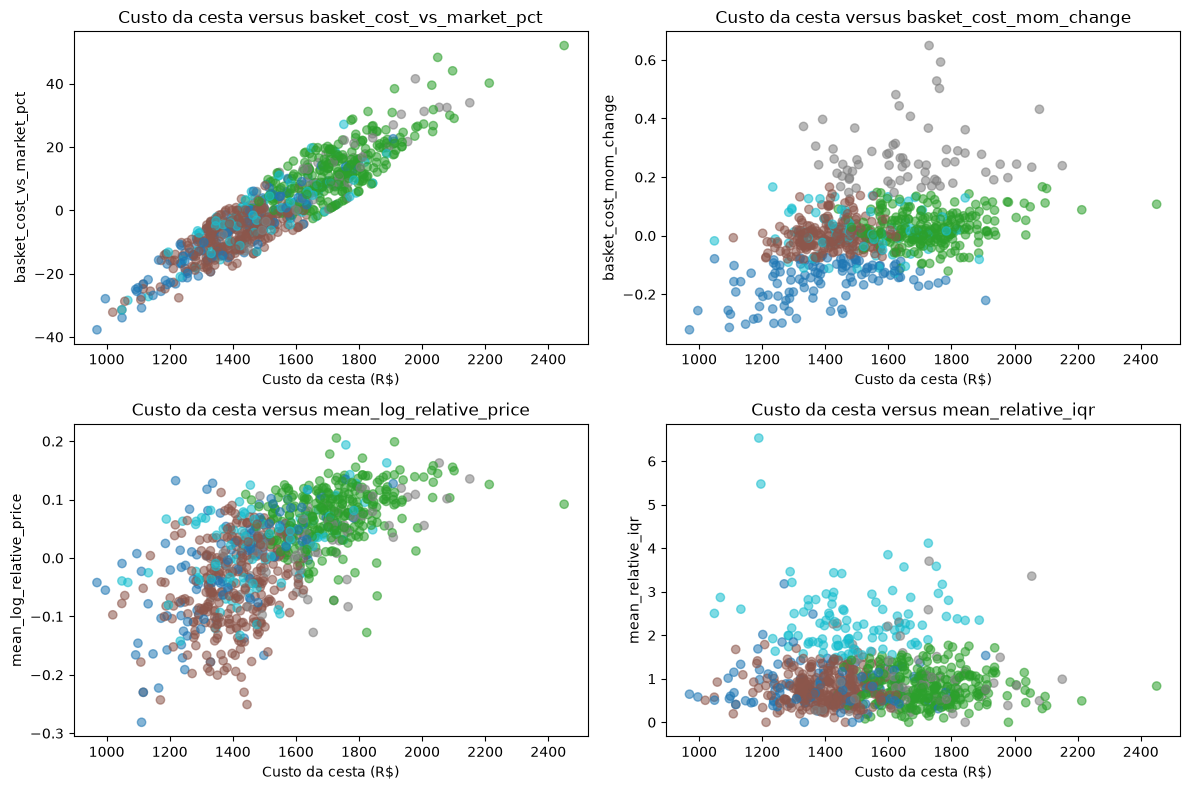

In [24]:
relationship_features = [
    "basket_cost_vs_market_pct",
    "basket_cost_mom_change",
    "mean_log_relative_price",
    "mean_relative_iqr",
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, feature in zip(axes.flat, relationship_features):
    plot_data = (
        gold_model.select(["basket_cost", feature])
        .with_columns(pl.Series("cluster", labels))
        .drop_nulls()
    )
    axis.scatter(
        plot_data["basket_cost"].to_numpy(),
        plot_data[feature].to_numpy(),
        c=plot_data["cluster"].to_numpy(),
        cmap="tab10",
        alpha=0.55,
    )
    axis.set_xlabel("Custo da cesta (R$)")
    axis.set_ylabel(feature)
    axis.set_title(f"Custo da cesta versus {feature}")
plt.tight_layout()

As features auxiliares da camada gold descrevem como a cesta foi montada e quão estável é a observação. `mean_log_relative_price` e `mean_relative_iqr` descrevem posição e dispersão dos preços dos produtos; `valid_price_products` e `sample_count` descrevem cobertura e volume de evidência. Elas ajudam a verificar se um cluster é um perfil de preços ou principalmente um perfil de cobertura dos dados.

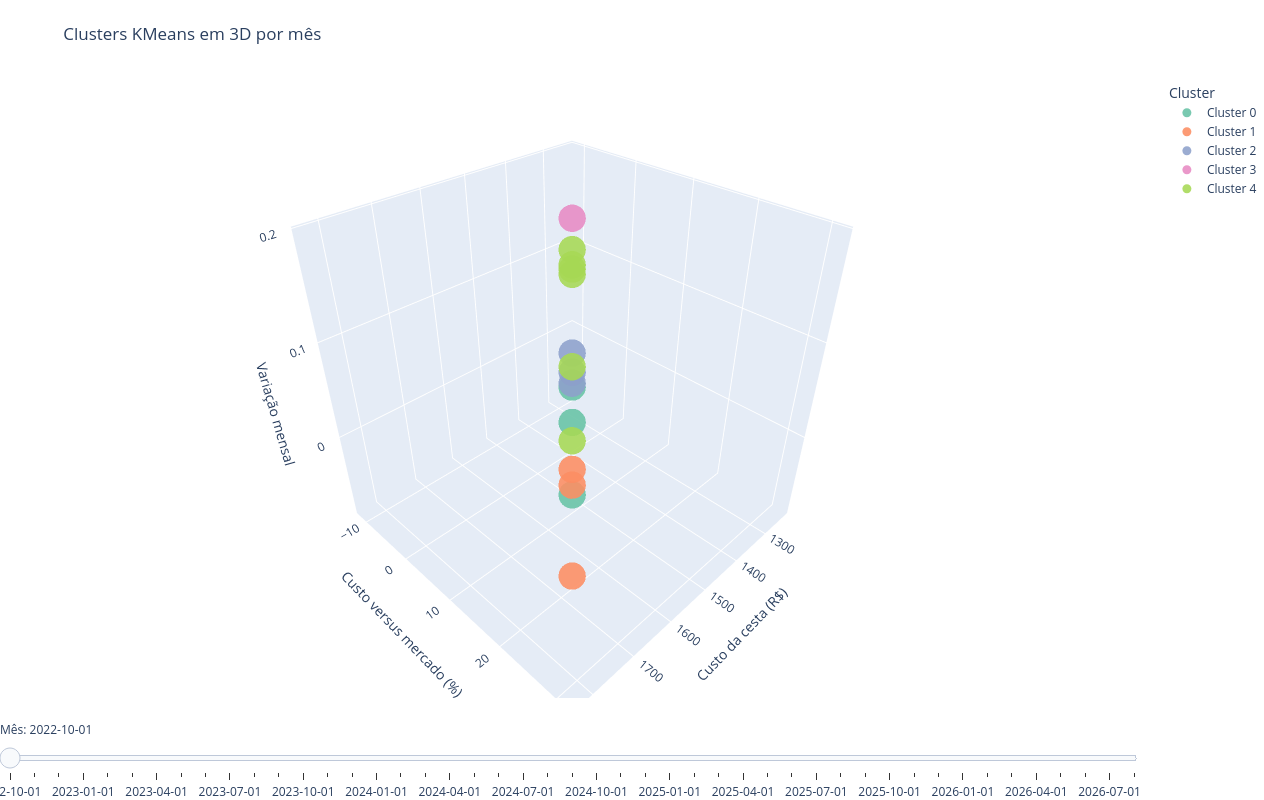

In [25]:
# Versão com slider: mostra um mês por vez e preserva os detalhes no hover.
def monthly_cluster_traces(month):
    month_data = plot_3d_data.filter(pl.col("reference_month") == month)
    traces = []
    for cluster in range(model_config.n_clusters):
        data = month_data.filter(pl.col("cluster") == cluster)
        stores = data["establishment_id"].to_list()
        traces.append(
            go.Scatter3d(
                x=data["basket_cost"].to_list(),
                y=data["basket_cost_vs_market_pct"].to_list(),
                z=data["basket_cost_mom_change"].to_list(),
                mode="markers",
                name=f"Cluster {cluster}",
                marker={
                    "size": 9,
                    "color": palette[cluster % len(palette)],
                    "opacity": 0.88,
                },
                customdata=[
                    [
                        store,
                        month,
                        basket_detail_lookup.get(
                            (store, month), "Detalhes não disponíveis"
                        ),
                    ]
                    for store in stores
                ],
                hovertemplate="<b>%{customdata[0]}</b> | %{customdata[1]}<br>Custo: R$ %{x:.2f}<br>Versus mercado: %{y:.2f}%<br>Variação mensal: %{z:.3f}<br><br><b>Detalhes</b><br>%{customdata[2]}<extra></extra>",
            )
        )
    return traces


fig_3d_time = go.Figure(data=monthly_cluster_traces(months[0]))
fig_3d_time.frames = [
    go.Frame(name=str(month), data=monthly_cluster_traces(month)) for month in months
]
fig_3d_time.update_layout(
    title="Clusters KMeans em 3D por mês",
    height=800,
    width=1200,
    scene={
        "xaxis_title": "Custo da cesta (R$)",
        "yaxis_title": "Custo versus mercado (%)",
        "zaxis_title": "Variação mensal",
    },
    sliders=[
        {
            "active": 0,
            "currentvalue": {"prefix": "Mês: "},
            "steps": [
                {
                    "label": str(month),
                    "method": "animate",
                    "args": [
                        [str(month)],
                        {
                            "mode": "immediate",
                            "frame": {"duration": 0, "redraw": True},
                            "transition": {"duration": 0},
                        },
                    ],
                }
                for month in months
            ],
        }
    ],
    legend={"title": "Cluster"},
    margin={"l": 0, "r": 0, "b": 0, "t": 80},
)
fig_3d_time.show()

### Análise de outliers e ambiguidade

KMeans assigns every row to a cluster. For observation $x_i$ and its assigned centroid $c_i$, the centroid distance is:

$$distance_i = \sqrt{\sum_{k=1}^{p}(x_{ik} - c_{ik})^2}$$

We flag the furthest 1% of distances inside each cluster. The individual silhouette is:

$$s_i = \frac{b_i-a_i}{\max(a_i,b_i)}$$

where $a_i$ is the average distance to the assigned cluster and $b_i$ is the smallest average distance to another cluster. Positive values indicate a better assignment; negative values indicate ambiguity. These observations should be investigated, not automatically deleted.

No gráfico interativo, a linha pontilhada representa `silhouette = 0`. Acima dela, a observação está mais próxima do próprio cluster do que dos demais; abaixo dela, a atribuição é ambígua. Os símbolos são separados: losango vermelho = outlier de distância; `x` roxo = atribuição ambígua; estrela laranja = as duas condições ao mesmo tempo.

### Visualização nas features originais

O modelo usa a matriz completa com cinco features. O PCA é apenas uma etapa de visualização. Para inspecionar o espaço original diretamente, podemos plotar duas features originais por vez; isso não altera o agrupamento.

In [26]:
outlier_summary = outliers.select(
    [
        pl.col("is_cluster_outlier").sum().alias("cluster_outliers"),
        pl.col("is_ambiguous_assignment").sum().alias("ambiguous_assignments"),
        pl.col("distance_to_centroid").quantile(0.99).alias("distance_p99"),
    ]
)
outlier_summary, outliers.sort("distance_to_centroid", descending=True).head(15)

(shape: (1, 3)
 ┌──────────────────┬───────────────────────┬──────────────┐
 │ cluster_outliers ┆ ambiguous_assignments ┆ distance_p99 │
 │ ---              ┆ ---                   ┆ ---          │
 │ u32              ┆ u32                   ┆ f64          │
 ╞══════════════════╪═══════════════════════╪══════════════╡
 │ 11               ┆ 54                    ┆ 3.26486      │
 └──────────────────┴───────────────────────┴──────────────┘,
 shape: (15, 7)
 ┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
 │ establishmen ┆ reference_m ┆ distance_to ┆ cluster_dis ┆ is_cluster_ ┆ silhouette_ ┆ is_ambiguou │
 │ t_id         ┆ onth        ┆ _centroid   ┆ tance_thres ┆ outlier     ┆ sample      ┆ s_assignmen │
 │ ---          ┆ ---         ┆ ---         ┆ hold        ┆ ---         ┆ ---         ┆ t           │
 │ str          ┆ date        ┆ f64         ┆ ---         ┆ bool        ┆ f64         ┆ ---         │
 │              ┆             ┆

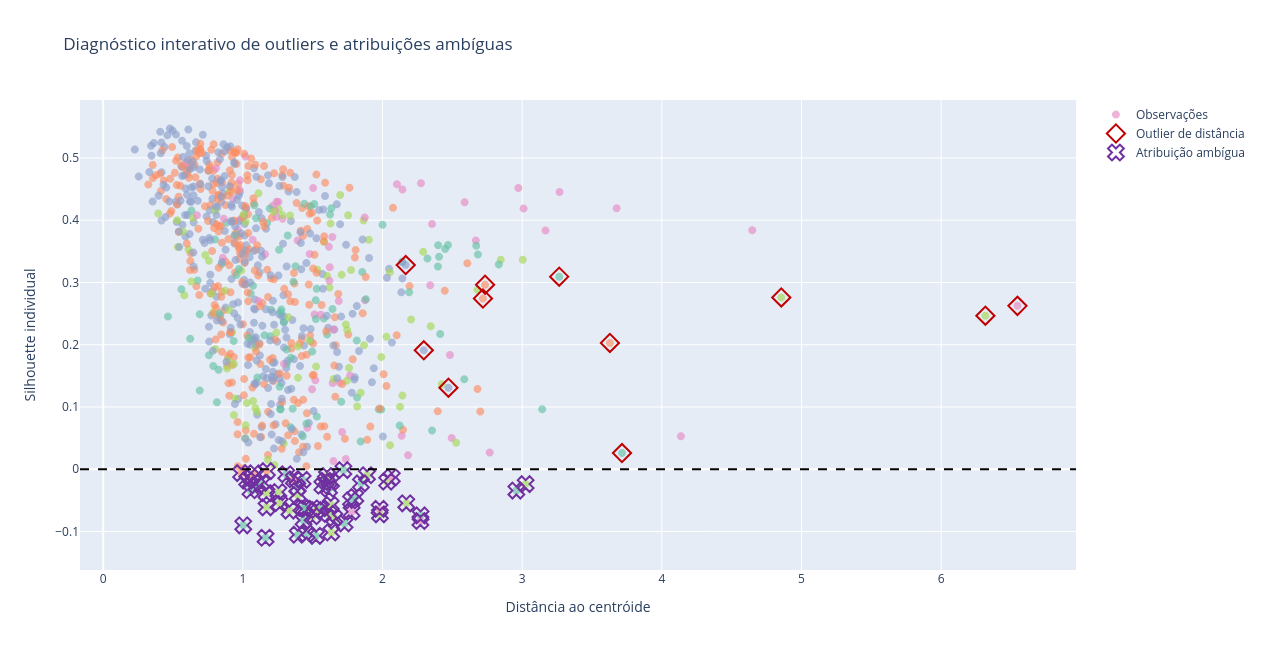

In [27]:
# Outliers interativos: o hover mostra o diagnóstico do cluster e os itens da cesta.
outlier_detail = outliers.join(
    assignments, on=["establishment_id", "reference_month"], how="left"
).join(
    gold_model.select(["establishment_id", "reference_month", *FEATURE_COLUMNS]),
    on=["establishment_id", "reference_month"],
    how="left",
)
detail_text = [
    basket_detail_lookup.get(
        (row["establishment_id"], row["reference_month"]), "Detalhes não disponíveis"
    )
    for row in outlier_detail.select(["establishment_id", "reference_month"]).to_dicts()
]
outlier_detail = outlier_detail.with_columns(pl.Series("basket_detail", detail_text))
outlier_rows = outlier_detail.to_dicts()


def outlier_status(row):
    if row["is_cluster_outlier"] and row["is_ambiguous_assignment"]:
        return "Outlier e ambígua"
    if row["is_cluster_outlier"]:
        return "Outlier de distância"
    if row["is_ambiguous_assignment"]:
        return "Atribuição ambígua"
    return "Normal"


customdata = [
    [
        row["establishment_id"],
        row["reference_month"],
        row["cluster"],
        row["distance_to_centroid"],
        row["cluster_distance_threshold"],
        row["silhouette_sample"],
        row["basket_cost"],
        row["basket_cost_vs_market_pct"],
        row["basket_cost_mom_change"],
        row["mean_log_relative_price"],
        row["mean_relative_iqr"],
        row["basket_detail"],
        outlier_status(row),
    ]
    for row in outlier_rows
]
hover_template = (
    "<b>%{customdata[0]}</b> | %{customdata[1]}<br>"
    "Cluster: %{customdata[2]}<br>Distância ao centróide: %{customdata[3]:.3f}<br>Limite do cluster: %{customdata[4]:.3f}<br>"
    "Silhouette individual: %{customdata[5]:.3f}<br>Custo da cesta: R$ %{customdata[6]:.2f}<br>"
    "Versus mercado: %{customdata[7]:.2f}%<br>Variação mensal: %{customdata[8]:.3f}<br>"
    "Preço relativo médio (log): %{customdata[9]:.3f}<br>IQR relativo médio: %{customdata[10]:.3f}<br><br>"
    "Classificação: %{customdata[12]}<br><br><b>Detalhes dos produtos</b><br>%{customdata[11]}"
)
fig_outliers = go.Figure()
fig_outliers.add_trace(
    go.Scatter(
        x=[row["distance_to_centroid"] for row in outlier_rows],
        y=[row["silhouette_sample"] for row in outlier_rows],
        mode="markers",
        name="Observações",
        customdata=customdata,
        marker={
            "size": 8,
            "color": [
                palette[int(row["cluster"]) % len(palette)] for row in outlier_rows
            ],
            "opacity": 0.65,
        },
        hovertemplate=hover_template + "<extra></extra>",
    )
)
flagged_groups = {
    "Outlier de distância": [
        row
        for row in outlier_rows
        if row["is_cluster_outlier"] and not row["is_ambiguous_assignment"]
    ],
    "Atribuição ambígua": [
        row
        for row in outlier_rows
        if row["is_ambiguous_assignment"] and not row["is_cluster_outlier"]
    ],
    "Outlier e ambígua": [
        row
        for row in outlier_rows
        if row["is_cluster_outlier"] and row["is_ambiguous_assignment"]
    ],
}
flagged_style = {
    "Outlier de distância": {"symbol": "diamond-open", "color": "#C00000"},
    "Atribuição ambígua": {"symbol": "x-open", "color": "#7030A0"},
    "Outlier e ambígua": {"symbol": "star-open", "color": "#ED7D31"},
}
for status, rows in flagged_groups.items():
    flagged_customdata = [
        [
            row["establishment_id"],
            row["reference_month"],
            row["cluster"],
            row["distance_to_centroid"],
            row["cluster_distance_threshold"],
            row["silhouette_sample"],
            row["basket_cost"],
            row["basket_cost_vs_market_pct"],
            row["basket_cost_mom_change"],
            row["mean_log_relative_price"],
            row["mean_relative_iqr"],
            row["basket_detail"],
            status,
        ]
        for row in rows
    ]
    style = flagged_style[status]
    fig_outliers.add_trace(
        go.Scatter(
            x=[row["distance_to_centroid"] for row in rows],
            y=[row["silhouette_sample"] for row in rows],
            mode="markers",
            name=status,
            customdata=flagged_customdata,
            marker={
                "size": 14,
                "symbol": style["symbol"],
                "color": style["color"],
                "line": {"width": 2},
            },
            hovertemplate=hover_template + "<extra></extra>",
        )
    )
fig_outliers.add_hline(y=0, line_dash="dash", line_color="black")
fig_outliers.update_layout(
    title="Diagnóstico interativo de outliers e atribuições ambíguas",
    xaxis_title="Distância ao centróide",
    yaxis_title="Silhouette individual",
    height=650,
    width=1200,
    hoverlabel={"align": "left"},
)
fig_outliers.show()

Explained variance ratio: [0.52396335 0.22707515]


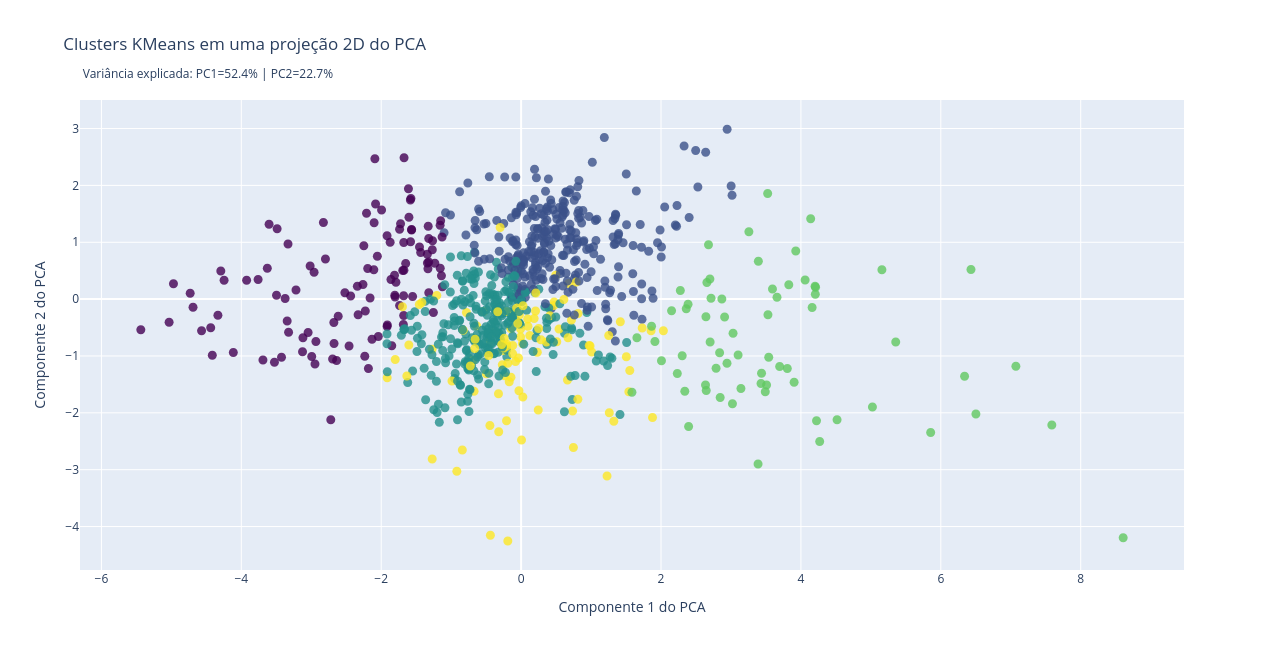

In [28]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
projection = pca.fit_transform(X_scaled)
pca_loadings = pl.DataFrame(
    {
        "feature": FEATURE_COLUMNS,
        "PC1_loading": pca.components_[0],
        "PC2_loading": pca.components_[1],
    }
)
pca_model = SklearnKMeans(model_config).fit(projection)
pca_labels = pca_model.predict(projection)
pca_metrics = evaluate_clustering(projection, pca_labels, pca_model.inertia)
model_comparison = pl.DataFrame(
    [
        {"model": "Full five features", **metrics},
        {"model": "Two PCA components", **pca_metrics},
    ]
)
print("Explained variance ratio:", pca.explained_variance_ratio_)
model_comparison, pca_loadings
pca_plot_rows = (
    gold_model.select(["establishment_id", "reference_month", *FEATURE_COLUMNS])
    .with_columns(
        [
            pl.Series("PC1", projection[:, 0]),
            pl.Series("PC2", projection[:, 1]),
            pl.Series("cluster", labels),
        ]
    )
    .to_dicts()
)
pca_customdata = [
    [
        row["establishment_id"],
        row["reference_month"],
        row["cluster"],
        *[row[feature] for feature in FEATURE_COLUMNS],
        basket_detail_lookup.get(
            (row["establishment_id"], row["reference_month"]),
            "Detalhes não disponíveis",
        ),
    ]
    for row in pca_plot_rows
]
pca_hover = (
    "<b>%{customdata[0]}</b> | %{customdata[1]}<br>Cluster: %{customdata[2]}<br>"
    "Custo: R$ %{customdata[3]:.2f}<br>Versus mercado: %{customdata[4]:.2f}%<br>Variação mensal: %{customdata[5]:.3f}<br>"
    "Preço relativo médio: %{customdata[6]:.3f}<br>IQR relativo médio: %{customdata[7]:.3f}<br><br>"
    "<b>Detalhes dos produtos</b><br>%{customdata[8]}<extra></extra>"
)
fig_pca = go.Figure(
    go.Scatter(
        x=[row["PC1"] for row in pca_plot_rows],
        y=[row["PC2"] for row in pca_plot_rows],
        mode="markers",
        customdata=pca_customdata,
        marker={"size": 9, "color": labels, "colorscale": "Viridis", "opacity": 0.8},
        hovertemplate=pca_hover,
    )
)
fig_pca.update_layout(
    title="Clusters KMeans em uma projeção 2D do PCA",
    xaxis_title="Componente 1 do PCA",
    yaxis_title="Componente 2 do PCA",
    height=650,
    width=1000,
    annotations=[
        {
            "text": f"Variância explicada: PC1={pca.explained_variance_ratio_[0]:.1%} | PC2={pca.explained_variance_ratio_[1]:.1%}",
            "xref": "paper",
            "yref": "paper",
            "x": 0,
            "y": 1.08,
            "showarrow": False,
        }
    ],
)
fig_pca.show()

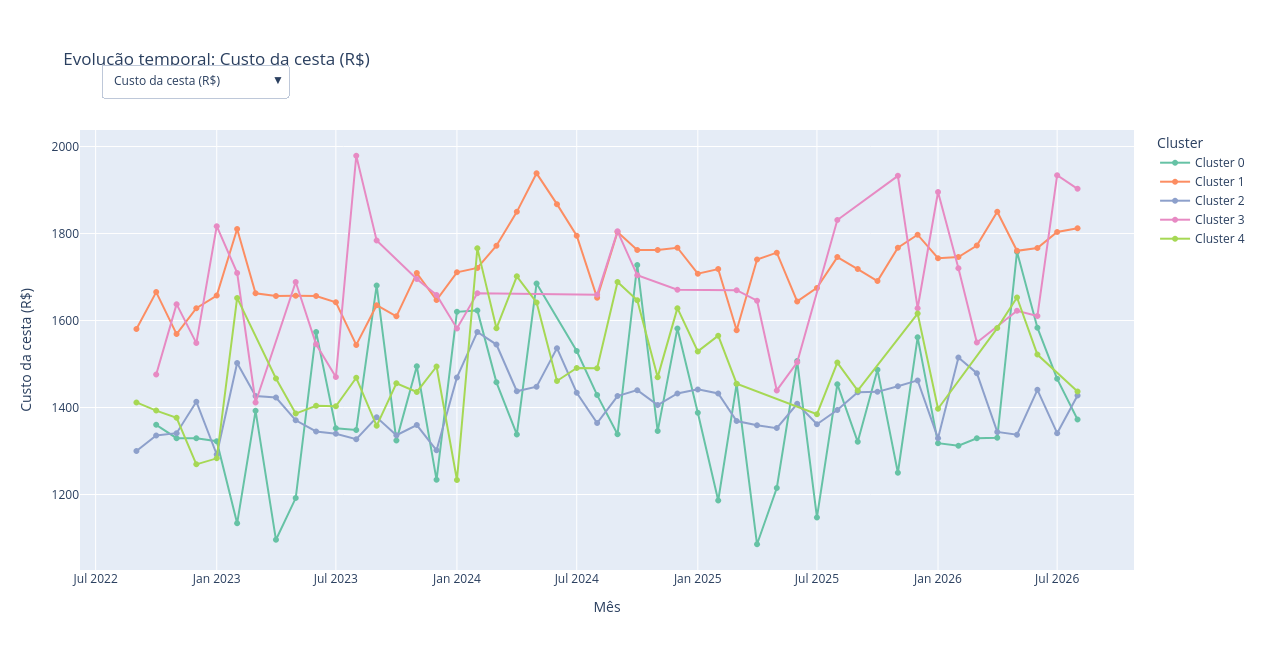

In [29]:
# Evolução temporal: média mensal de cada feature dentro de cada cluster.
cluster_time = (
    gold_model.with_columns(pl.Series("cluster", labels))
    .group_by(["reference_month", "cluster"])
    .agg([pl.col(feature).mean().alias(feature) for feature in FEATURE_COLUMNS])
    .sort(["reference_month", "cluster"])
)


def time_series_for(feature):
    return [
        cluster_time.filter(pl.col("cluster") == cluster)
        for cluster in range(model_config.n_clusters)
    ]


initial_feature = "basket_cost"
initial_series = time_series_for(initial_feature)
fig_feature_time = go.Figure()
for cluster, data in enumerate(initial_series):
    fig_feature_time.add_trace(
        go.Scatter(
            x=data["reference_month"].to_list(),
            y=data[initial_feature].to_list(),
            mode="lines+markers",
            name=f"Cluster {cluster}",
            line={"color": palette[cluster % len(palette)]},
            hovertemplate=f"Cluster {cluster}<br>%{{x}}<br>%{{y:.3f}}<extra></extra>",
        )
    )
feature_buttons = []
for feature in FEATURE_COLUMNS:
    series = time_series_for(feature)
    feature_buttons.append(
        {
            "label": feature_labels[feature],
            "method": "update",
            "args": [
                {
                    "x": [data["reference_month"].to_list() for data in series],
                    "y": [data[feature].to_list() for data in series],
                },
                {
                    "title": f"Evolução temporal: {feature_labels[feature]}",
                    "yaxis": {"title": feature_labels[feature]},
                },
            ],
        }
    )
fig_feature_time.update_layout(
    title=f"Evolução temporal: {feature_labels[initial_feature]}",
    xaxis_title="Mês",
    yaxis_title=feature_labels[initial_feature],
    height=650,
    width=1200,
    updatemenus=[
        {
            "buttons": feature_buttons,
            "direction": "down",
            "x": 0.02,
            "y": 1.15,
            "xanchor": "left",
            "yanchor": "top",
            "showactive": True,
        }
    ],
    margin={"t": 130},
    legend={"title": "Cluster"},
)
fig_feature_time.show()

## 8. Referências e guia de interpretação

- Polars lazy dataframes: https://docs.pola.rs/user-guide/concepts/lazy-api/
- scikit-learn KMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- scikit-learn clustering evaluation: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
- Silhouette coefficient: Rousseeuw (1987), https://doi.org/10.1016/0377-0427(87)90125-7
- Bronze/silver/gold data layers: Databricks medallion architecture, https://www.databricks.com/glossary/medallion-architecture
- DIEESE basket methodology and national quantities: https://www.dieese.org.br/metodologia/metodologiaCestaBasica2025/index.html?page=1
- Decreto nº 11.936/2024: https://legislacao.presidencia.gov.br/atos/?ano=2024&ato=883UTWE1ENZpWTa7d&numero=11936&tipo=DEC

The national quantities are used to calculate a standardized basket cost. `basket_cost_vs_market_pct` is the percentage difference between an establishment's complete basket and the median complete basket in the same month. A higher silhouette generally indicates better separation, but it is not proof that the clusters are substantively meaningful. Read the profiles, basket coverage, and data-quality flags together.